In [1]:
# Importamos lo necesario
import pandas as pd
import wget
from os import path, listdir
import numpy as np
import re
import ydata_profiling as pp
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

/tmp/ipykernel_83113/2419300301.py:7: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  import ydata_profiling as pp


In [1]:
# Leemos el dataset
raw_dataset_results = pd.read_csv("results.csv")
schema_dataset = pd.read_csv("schema.csv")
# 1. Definición de las listas de columnas para cada subgrupo
cols_g1 = ['Country', 'WorkExp', 'ConvertedCompYearly', 'CompTotal', 
           'Currency', 'Age', 'EdLevel', 'Employment', 'YearsCode']

cols_g2 = ['WorkExp', 'AIAcc', 'JobSat', 'AISent', 'AISelect', 'AIThreat', 'AILearnHow']

# Para el Grupo 3 extraemos dinámicamente todas las de JobSatPoints (del 1 al 15 + TEXT) para evitar hardcodearlas
cols_jobsat = [col for col in raw_dataset_results.columns if col.startswith('JobSatPoints')]
cols_g3 = ['NewRole', 'JobSat'] + cols_jobsat

cols_g4 = ['ConvertedCompYearly', 'WorkExp', 'OrgSize', 'AISelect', 'RemoteWork', 'DevType', 'Industry', 'ICorPM']

# 2. Creación de los DataFrames independientes para cada subgrupo
# Usamos .copy() para que cada compañero pueda limpiar nulos o transformar datos sin afectar el dataset original

# Subgrupo 1: Perfil Económico (Para Hipótesis 1 y HU1)
df_perfil_economico = raw_dataset_results[cols_g1].copy()

# Subgrupo 2: Impacto de la IA (Para Hipótesis B y HB1)
df_impacto_ia = raw_dataset_results[cols_g2].copy()

# Subgrupo 3: Cambio de Rol (Para Hipótesis C)
df_cambio_rol = raw_dataset_results[cols_g3].copy()

# Subgrupo 4: Premio Salarial (Para Hipótesis M4)
df_premio_salarial = raw_dataset_results[cols_g4].copy()

NameError: name 'pd' is not defined

**Hipotesis** Mas del 50% de los encuestados argentinos tiene < 3 años de experiencia, que es el umbral para posiciones mid-level (umbral de concenso generalizado obtenido por Gemini cruzando Matrices públicas de las Grandes Tecnológicas (Big Tech), Ofertas de empleo y datos de portales de reclutamiento (Aggregated Job Boards) y Repositorios de Código Abierto sobre Progresión Profesional)

In [3]:
# Dado que hay demasiadas columnas elegimos las que mas nos interesan

In [4]:
encuestados_argentina_hipotesis1 = df_perfil_economico[df_perfil_economico["Country"]=="Argentina"].copy()
encuestados_argentina_hipotesis1[["WorkExp"]].info()

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 88 to 48790
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   WorkExp  200 non-null    float64
dtypes: float64(1)
memory usage: 3.5 KB


In [5]:
# Podemos observar que de 222 entradas, 200 son no nulas
filas_nulos = encuestados_argentina_hipotesis1[encuestados_argentina_hipotesis1["WorkExp"].isna()]
filas_nulos

,Country,WorkExp,ConvertedCompYearly,CompTotal,Currency,Age,EdLevel,Employment,YearsCode
1329,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,25-34 years old,Some college/university study without earning ...,Not employed,6.0
6761,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,Some college/university study without earning ...,Student,5.0
6762,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,"Secondary school (e.g. American high school, G...",Student,7.0
9232,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,Some college/university study without earning ...,Student,1.0
10240,Argentina,NaN,NaN,0.0,ARS\tArgentine peso,18-24 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Student,6.0
11464,Argentina,NaN,NaN,NaN,USD United States dollar,25-34 years old,Some college/university study without earning ...,Not employed,10.0
12329,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,25-34 years old,Some college/university study without earning ...,Student,8.0
13592,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,Some college/university study without earning ...,Employed,2.0
13743,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,18-24 years old,"Secondary school (e.g. American high school, G...",Student,2.0
14019,Argentina,NaN,NaN,NaN,ARS\tArgentine peso,25-34 years old,Some college/university study without earning ...,Student,2.0


In [6]:
# Podemos observar que quienes no respondieron a la pregunta sobre los años de experiencia trabajando, son de perfiles distintos
filas_nulos["Employment"].unique()

array(['Not employed', 'Student', 'Employed',
       'Independent contractor, freelancer, or self-employed'],
      dtype=object)

In [7]:
# Ya que la mayoria son estudiantes o no empleados, procedemos a colocarles los años de experiencia en 0

encuestados_argentina_hipotesis1["WorkExp"] = 
    encuestados_argentina_hipotesis1["WorkExp"].fillna(0)

encuestados_argentina_hipotesis1["WorkExp"].info()

<class 'pandas.core.series.Series'>
Index: 222 entries, 88 to 48790
Series name: WorkExp
Non-Null Count  Dtype  
--------------  -----  
222 non-null    float64
dtypes: float64(1)
memory usage: 3.5 KB


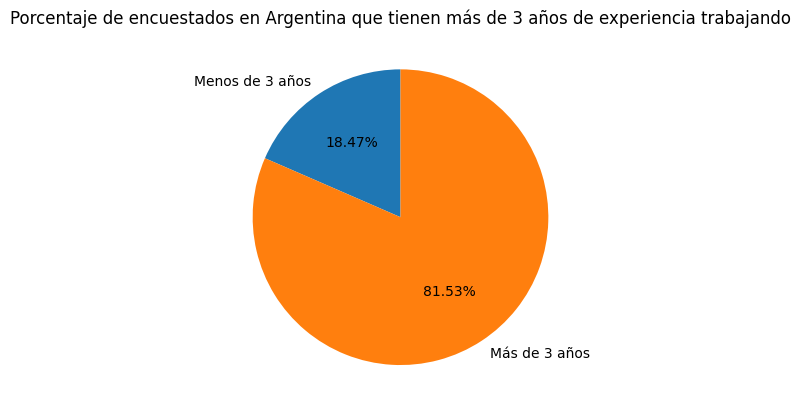

In [10]:
experiencia_encuestados_argentina = encuestados_argentina_hipotesis1["WorkExp"]
supera = (experiencia_encuestados_argentina >= 3.0).sum()
no_supera = (experiencia_encuestados_argentina < 3.0).sum()

plt.pie(
    [no_supera, supera],
    labels=["Menos de 3 años", "Más de 3 años"],
    autopct="%1.2f%%",
    startangle=90,
)
plt.title("Porcentaje de encuestados en Argentina que 
tienen más de 3 años de experiencia trabajando")
plt.show()